# ML CSAI500 Module 2 Teaching Notebook

## End-to-End Machine Learning Workflow

**Instructor demonstration **

This notebook follows Module 2 and Geron's end-to-end California housing project. It demonstrates problem framing, data inspection, EDA, splitting, preprocessing, pipelines, baselines, cross-validation, grid search, and final testing. The comments are written for live teaching: pause, ask students to predict, run the cell, then interpret the result.

## Learning objectives

Students should be able to:

- frame a real-world objective as a regression problem;
- distinguish features from the target;
- use statistics and plots for exploratory data analysis;
- explain why the test set must be protected;
- handle missing values and scale numerical features;
- explain why pipelines reduce inconsistency and data leakage;
- compare a baseline and learned models;
- use cross-validation and grid search;
- interpret RMSE and MAE.

## Setup and problem framing

The California housing task predicts `MedHouseVal` from district-level features. Before coding, ask: Who uses the predictions? What is the cost of overestimating or underestimating? Which errors matter most? These questions determine the useful metric and constraints.

In [1]:
# Install once if needed:
# %pip install pandas numpy matplotlib scikit-learn joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
pd.set_option('display.max_columns',20)
RANDOM_STATE=42

In [6]:
# California housing is a regression problem: predict median house value.
# The first run may download the data.
housing=fetch_california_housing(as_frame=True)
df=housing.frame.copy()
print('Shape:',df.shape)
display(df.head())

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 1. Understand the data structure

`info()` shows data types and non-null counts. `describe()` shows scale, central tendency, and spread. The missing-value check tells us whether an imputation step is needed.

**Teaching question:** Which information would you inspect before choosing a model?

## The complete end-to-end workflow

The diagram summarizes the project lifecycle. It is iterative: after deployment, monitoring and new data may send us back to problem definition, data collection, or feature engineering.

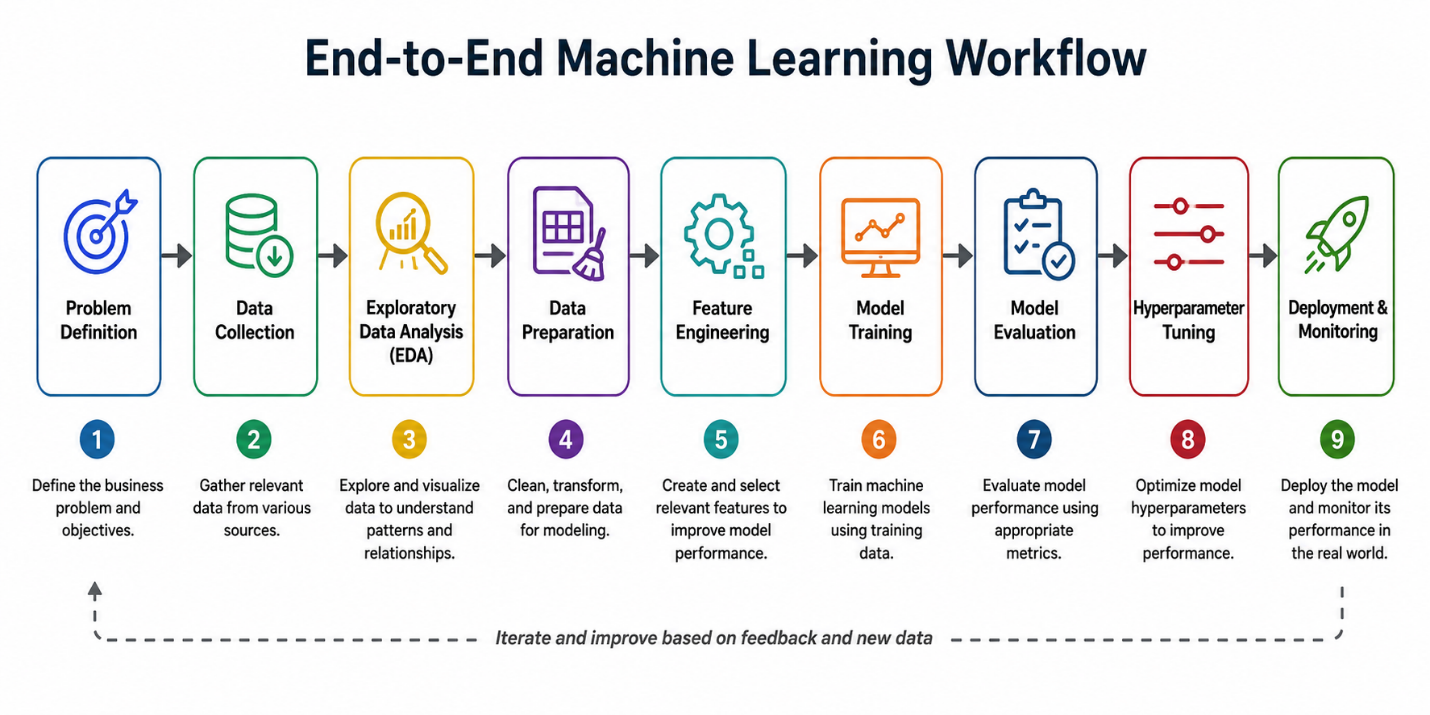

**Teaching prompt:** Ask students which steps can introduce data leakage and which steps must be repeated when new data arrives.

In [7]:
# These checks are part of modeling, not optional decoration.
df.info()
display(df.describe().T)
print('Missing values:')
display(df.isna().sum().sort_values(ascending=False).head())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Missing values:


MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
dtype: int64

## Data-quality demonstration

Before modeling, students should understand that data preparation is a reasoning task, not just a collection of commands. Missing values, duplicates, outliers, inconsistent categories, and biased sampling can all affect the result.

The small example below shows the questions practitioners ask before choosing an imputation strategy. Removing rows may discard information; replacing values may introduce assumptions; an outlier may be an error or a rare but legitimate case.


In [8]:
# A small artificial table for discussing data-quality decisions.
quality_demo = pd.DataFrame({
    "Age": [22, 35, np.nan, 41, 190],
    "Income": [42000, 68000, 52000, np.nan, 71000],
    "Plan": ["Basic", "Premium", "Basic", "Premium", "Unknown"],
})
display(quality_demo)
print("Missing values:")
display(quality_demo.isna().sum())
print("Duplicate rows:", quality_demo.duplicated().sum())

# Teaching question: should Age=190 be removed automatically?
# Answer: investigate first; it may be a data-entry error, but automatic deletion
# can also remove rare but valid cases in other datasets.


,Age,Income,Plan
0,22.0,42000.0,Basic
1,35.0,68000.0,Premium
2,NaN,52000.0,Basic
3,41.0,NaN,Premium
4,190.0,71000.0,Unknown


Missing values:


Age       1
Income    1
Plan      0
dtype: int64

Duplicate rows: 0


## Categorical variables and scaling

Module 2 distinguishes several data types:

- numerical data, such as age or income;
- categorical data, such as country or product type;
- ordinal data, such as satisfaction levels with a meaningful order;
- text data, such as reviews or comments.

For nominal categories, one-hot encoding is usually safer than assigning arbitrary numbers. Scaling is important for models that use distances or optimization; it is less important for tree-based models, which split on thresholds.


In [10]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

category_demo = pd.DataFrame({
    "Income": [25000, 50000, 90000, 70000],
    "Color": ["Red", "Blue", "Green", "Red"],
})

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded_colors = encoder.fit_transform(category_demo[["Color"]])
encoded = pd.DataFrame(encoded_colors, columns=encoder.get_feature_names_out(["Color"]))
display(pd.concat([category_demo[["Income"]], encoded], axis=1))

# Normalization maps values to a fixed range, commonly 0 to 1.
normalized_income = MinMaxScaler().fit_transform(category_demo[["Income"]])
print("Normalized income:", normalized_income.ravel().round(2))

# Standardization centers values around 0 with standard deviation about 1.
standardized_income = StandardScaler().fit_transform(category_demo[["Income"]])
print("Standardized income:", standardized_income.ravel().round(2))


,Income,Color_Blue,Color_Green,Color_Red
0,25000,0.0,0.0,1.0
1,50000,1.0,0.0,0.0
2,90000,0.0,1.0,0.0
3,70000,0.0,0.0,1.0


Normalized income: [0.   0.38 1.   0.69]
Standardized income: [-1.4  -0.36  1.3   0.47]


## 2. Exploratory data analysis

Histograms reveal distributions, skewness, and possible outliers. Correlation can reveal linear relationships, but it is not proof of causation and may miss nonlinear patterns.

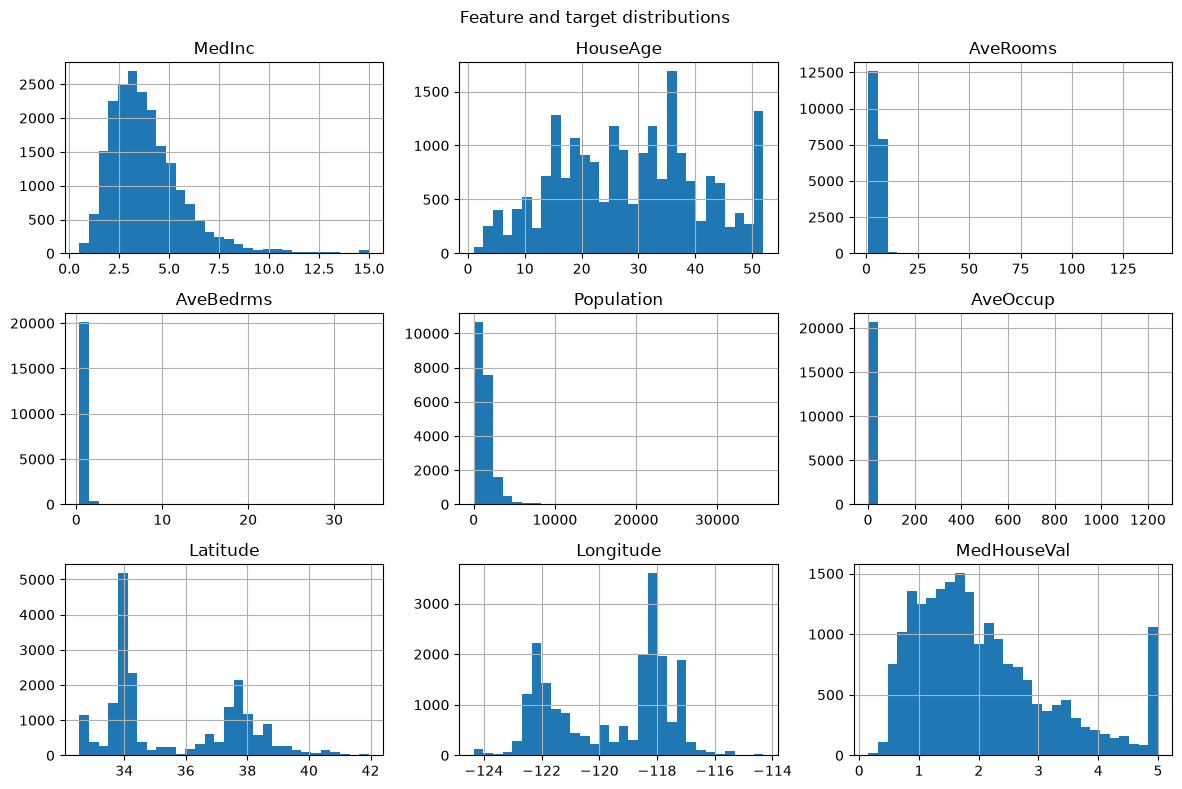

In [11]:
df.hist(figsize=(12,8),bins=30)
plt.suptitle('Feature and target distributions')
plt.tight_layout()
plt.show()

,correlation with target
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


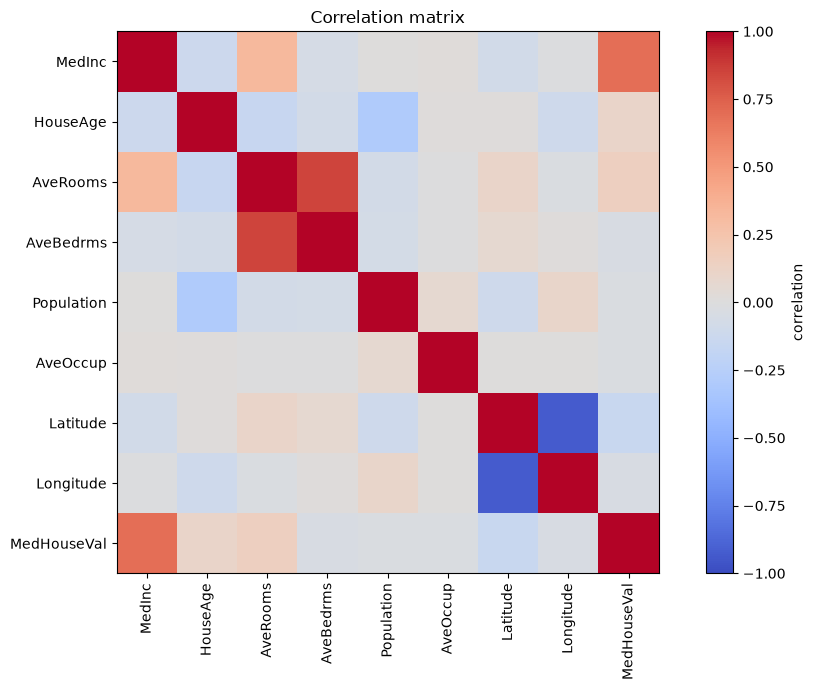

In [12]:
corr=df.corr(numeric_only=True)
display(corr['MedHouseVal'].sort_values(ascending=False).to_frame('correlation with target'))
plt.figure(figsize=(10,7))
plt.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
plt.colorbar(label='correlation')
plt.xticks(range(len(corr.columns)),corr.columns,rotation=90)
plt.yticks(range(len(corr.columns)),corr.columns)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

## 3. Split the data before learning transformations

The target is `MedHouseVal`; all other columns are features. The test set represents future unseen data. We must learn imputation and scaling statistics from training data only. Otherwise, information leaks from the test set into training.

In [ ]:
X=df.drop(columns='MedHouseVal')
y=df['MedHouseVal']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
print('Training rows:',len(X_train))
print('Test rows:',len(X_test))

Training rows: 16512
Test rows: 4128


## Data preparation concepts from Module 2

Real-world data is rarely ready for modeling.

- **Missing values:** inspect them first; possible strategies include removal, median imputation, or a more advanced method.
- **Outliers:** investigate whether they are errors or rare but valid observations before removing them.
- **Categorical variables:** label encoding can introduce a false order; one-hot encoding is usually safer for nominal categories.
- **Feature scaling:** normalization maps values to a fixed range, often 0 to 1; standardization centers values around mean 0 with standard deviation 1.
- **Feature engineering:** create useful variables such as rooms per household.
- **Feature selection:** remove irrelevant or redundant variables to improve speed, interpretability, and sometimes generalization.

Our California housing features are numerical, so this notebook demonstrates imputation and standardization. In a mixed-type dataset, a `ColumnTransformer` would use separate numerical and categorical pipelines.

In [14]:
# Example feature engineering: create a more interpretable ratio.
# The source variables are already available in the California housing data.
df_demo = df.copy()
df_demo['RoomsPerHousehold'] = df_demo['AveRooms'] / df_demo['AveOccup']
df_demo['BedroomsPerRoom'] = df_demo['AveBedrms'] / df_demo['AveRooms']
display(df_demo[['AveRooms', 'AveOccup', 'RoomsPerHousehold', 'BedroomsPerRoom']].head())

# Teaching point: engineered features can express relationships more directly.
# They must be created without using information from the future or the target itself.

,AveRooms,AveOccup,RoomsPerHousehold,BedroomsPerRoom
0,6.984127,2.555556,2.732919,0.146591
1,6.238137,2.109842,2.956685,0.155797
2,8.288136,2.802260,2.957661,0.129516
3,5.817352,2.547945,2.283154,0.184458
4,6.281853,2.181467,2.879646,0.172096


## 4. Prepare features with a pipeline

The pipeline fills missing numerical values with the median and standardizes features. A pipeline makes the process reproducible and applies the same preparation during training, validation, testing, and future prediction. `fit_transform` learns statistics and applies them to training data; `transform` applies learned statistics to new data.

In [15]:
numeric_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
preprocessor=ColumnTransformer([('numeric',numeric_pipeline,list(X.columns))])
X_train_prepared=preprocessor.fit_transform(X_train)
X_test_prepared=preprocessor.transform(X_test)
print('Prepared shapes:',X_train_prepared.shape,X_test_prepared.shape)

Prepared shapes: (16512, 8) (4128, 8)


## 5. Establish a baseline and train models

A baseline predicts the training mean. It answers: How much value does machine learning add? We compare it with linear regression and a random forest. A lower training error is not automatically better because a flexible model can memorize training examples.

In [ ]:
baseline=DummyRegressor(strategy='mean')
baseline.fit(X_train,y_train)
baseline_rmse=mean_squared_error(y_train,baseline.predict(X_train))**0.5
linear_pipeline=Pipeline([('preprocessor',preprocessor),('model',LinearRegression())])
linear_pipeline.fit(X_train,y_train)
linear_rmse=mean_squared_error(y_train,linear_pipeline.predict(X_train))**0.5
forest_pipeline=Pipeline([('preprocessor',preprocessor),('model',RandomForestRegressor(n_estimators=50,random_state=42,n_jobs=-1))])
forest_pipeline.fit(X_train,y_train)
forest_rmse=mean_squared_error(y_train,forest_pipeline.predict(X_train))**0.5
print('Baseline RMSE:',round(baseline_rmse,3))
print('Linear RMSE:',round(linear_rmse,3))
print('Forest RMSE:',round(forest_rmse,3))

Baseline RMSE: 1.156
Linear RMSE: 0.72
Forest RMSE: 0.193


## 6. Cross-validation

Cross-validation uses several training/validation folds and gives a more stable estimate than one split. Scikit-learn returns negative RMSE because its scoring convention treats larger scores as better, so we change the sign back.

In [17]:
def cv_rmse(model,X_data,y_data):
    scores=cross_val_score(model,X_data,y_data,scoring='neg_root_mean_squared_error',cv=5,n_jobs=-1)
    return -scores
linear_scores=cv_rmse(linear_pipeline,X_train,y_train)
forest_scores=cv_rmse(forest_pipeline,X_train,y_train)
print('Linear fold RMSE:',linear_scores.round(3))
print('Linear mean/std:',round(linear_scores.mean(),3),round(linear_scores.std(),3))
print('Forest fold RMSE:',forest_scores.round(3))
print('Forest mean/std:',round(forest_scores.mean(),3),round(forest_scores.std(),3))

Linear fold RMSE: [0.721 0.709 0.721 0.713 0.739]
Linear mean/std: 0.721 0.01
Forest fold RMSE: [0.514 0.518 0.51  0.507 0.518]
Forest mean/std: 0.513 0.004


## 7. Hyperparameter optimization

Hyperparameters are choices such as number of trees and maximum features. Grid search evaluates specified combinations using cross-validation. Use a small grid so students can understand the process.

In [19]:
param_grid={'model__n_estimators':[30,60],'model__max_features':[0.7,1.0],'model__max_depth':[None,15]}
grid_search=GridSearchCV(forest_pipeline,param_grid,cv=3,scoring='neg_root_mean_squared_error',n_jobs=-1)
grid_search.fit(X_train,y_train)
print('Best parameters:',grid_search.best_params_)
print('Best CV RMSE:',round(-grid_search.best_score_,3))

Best parameters: {'model__max_depth': None, 'model__max_features': 0.7, 'model__n_estimators': 60}
Best CV RMSE: 0.511


## Choosing a performance measure

A metric is not just a number. It expresses what we consider a good prediction. The correct metric depends on the problem and the cost of different errors.

### Classification metrics

For a binary classifier, begin with the confusion matrix:

- **True positive (TP):** predicted positive and actually positive.
- **True negative (TN):** predicted negative and actually negative.
- **False positive (FP):** predicted positive but actually negative.
- **False negative (FN):** predicted negative but actually positive.

Definitions:

- **Accuracy** = `(TP + TN) / (TP + TN + FP + FN)`. It is the proportion of all predictions that are correct. It can be misleading with imbalanced classes.
- **Precision** = `TP / (TP + FP)`. Of the cases predicted positive, how many were actually positive? Precision matters when false positives are costly.
- **Recall** = `TP / (TP + FN)`. Of the actual positive cases, how many did the model find? Recall matters when missing a positive case is costly.
- **F1 score** = `2 × (precision × recall) / (precision + recall)`. It balances precision and recall.

### Regression metrics

- **MAE** is the average absolute difference between actual and predicted values. It is in the same units as the target and is easier to interpret.
- **RMSE** is the square root of the average squared error. It gives greater influence to large errors.

**Teaching question:** In a disease-screening system, would you prioritize precision, recall, or accuracy? Explain the cost of each error.

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# A small example makes the definitions concrete.
actual = [1, 1, 1, 1, 0, 0, 0, 0]
predicted = [1, 1, 0, 1, 1, 0, 0, 0]

print('Accuracy :', accuracy_score(actual, predicted))
print('Precision:', precision_score(actual, predicted))
print('Recall   :', recall_score(actual, predicted))
print('F1 score :', f1_score(actual, predicted))

# Ask students to identify TP, TN, FP, and FN by inspecting the two lists.

Accuracy : 0.75
Precision: 0.75
Recall   : 0.75
F1 score : 0.75


## Mini-example: classification metrics

The California housing model is a regression model, so RMSE and MAE are appropriate. Module 2 also introduces classification metrics. Use this short example to show why one metric is not always enough.

In a medical screening problem, a **false negative** can be more serious than a false positive, so recall may matter more than accuracy. In an expensive investigation system, false positives may be costly, so precision may matter more.


In [22]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X_cls, y_cls = make_classification(
    n_samples=500, n_features=6, n_informative=3,
    weights=[0.85, 0.15], random_state=42
)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=42
)

classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42)),
])
classifier.fit(Xc_train, yc_train)
yc_pred = classifier.predict(Xc_test)

print("Accuracy :", round(accuracy_score(yc_test, yc_pred), 3))
print("Precision:", round(precision_score(yc_test, yc_pred), 3))
print("Recall   :", round(recall_score(yc_test, yc_pred), 3))
print("F1 score :", round(f1_score(yc_test, yc_pred), 3))
print("Confusion matrix:\n", confusion_matrix(yc_test, yc_pred))

# Teaching point: with imbalanced classes, accuracy can look good even when
# the model misses too many positive cases. Always inspect the confusion matrix.


Accuracy : 0.944
Precision: 0.842
Recall   : 0.8
F1 score : 0.821
Confusion matrix:
 [[102   3]
 [  4  16]]


## 8. Final test evaluation

Use the test set once, after model decisions are complete. RMSE penalizes large errors more strongly; MAE is the average absolute error and is often easier to explain.

In [23]:
final_model=grid_search.best_estimator_
predictions=final_model.predict(X_test)
test_rmse=mean_squared_error(y_test,predictions)**0.5
test_mae=mean_absolute_error(y_test,predictions)
print('Final test RMSE:',round(test_rmse,3))
print('Final test MAE:',round(test_mae,3))
display(pd.DataFrame({'actual':y_test,'prediction':predictions}).head(10).round(2))

Final test RMSE: 0.5
Final test MAE: 0.325


,actual,prediction
20046,0.48,0.48
3024,0.46,0.71
15663,5.00,4.92
20484,2.19,2.60
9814,2.78,2.30
13311,1.59,1.73
7113,1.98,2.46
7668,1.58,1.68
18246,3.40,2.48
5723,4.47,4.83


## Parameters, hyperparameters, and search strategies

A **model parameter** is learned from data, such as the coefficients in linear regression. A **hyperparameter** is chosen by the practitioner, such as the number of trees in a random forest or its maximum depth.

- **Grid search** evaluates every combination in a small, explicitly defined grid. It is easy to understand but can become expensive.
- **Randomized search** samples combinations from larger ranges. It is useful when the search space is large and often reaches a good solution faster.

The best hyperparameters are selected using validation or cross-validation, not by repeatedly looking at the final test set.

## From notebook to production

A model is not finished when a score is printed. Before deployment, ask:

- Is the data available at prediction time?
- Is the performance acceptable for each important subgroup?
- What happens when the data distribution changes?
- How will predictions and errors be monitored?
- Can the preprocessing and model be reproduced?
- Is the model’s output understandable enough for stakeholders?

This is why Module 2 is an end-to-end workflow rather than only a model-training lesson.

## Feature engineering and feature selection

Feature engineering creates variables that express useful relationships more directly. In housing data, `rooms per household` may be more informative than raw room count alone. Feature selection removes irrelevant or redundant variables, which can improve speed, interpretability, and generalization.

Ask students: does adding a feature always improve a model? No. An irrelevant or leakage-prone feature can make the model worse or produce an unrealistically optimistic score.


In [25]:
# Create interpretable ratios from the housing features.
df_features = df.copy()
df_features["RoomsPerHousehold"] = df_features["AveRooms"] / df_features["AveOccup"]
df_features["BedroomsPerRoom"] = df_features["AveBedrms"] / df_features["AveRooms"]
display(df_features[["AveRooms", "AveOccup", "RoomsPerHousehold", "BedroomsPerRoom"]].head())

# These engineered features should be created consistently for future data too.


,AveRooms,AveOccup,RoomsPerHousehold,BedroomsPerRoom
0,6.984127,2.555556,2.732919,0.146591
1,6.238137,2.109842,2.956685,0.155797
2,8.288136,2.802260,2.957661,0.129516
3,5.817352,2.547945,2.283154,0.184458
4,6.281853,2.181467,2.879646,0.172096


## Deployment, monitoring, and responsible use

The project is not finished when the notebook prints a score. Before deployment, ask:

- Is the data available at prediction time?
- Is performance acceptable for important groups?
- What happens when the data distribution changes?
- How will predictions and errors be monitored?
- Can the entire preprocessing and model workflow be reproduced?
- Is the output understandable enough for stakeholders?

This is why Module 2 presents machine learning as an end-to-end workflow rather than only a model-training exercise.


## Closing discussion

Ask students:

1. What did the baseline tell us?
2. Why can cross-validation be more reliable than one split?
3. How does the pipeline reduce leakage and inconsistency?
4. Which model would you choose and why?
5. What additional checks would be needed before deployment?

The final score is an estimate, not a guarantee. Real projects also require monitoring, fairness checks, drift checks, and a metric connected to stakeholder costs.